# Predicting sensitivity and resistance

An XGBoost classifier over the unambiguous sgRNAs, those whose predicted edits comprise a
single genomic change, so the measured phenotype belongs to one mutation. Every
consequence class is kept, from missense and nonsense through silent, splice and
untranslated, which is what lets the decision space be read against mutation category.

Training uses this study only. The validation screen is scored by the trained model and
never trained on.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import umap
from adjustText import adjust_text
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import config as C
import src
from src import save_plot, ticked_axis

CLASSES = ["sensitivity", "neutral", "resistance"]
CLASS_INDEX = {name: position for position, name in enumerate(CLASSES)}
CLASS_COLOUR = {"sensitivity": "#009ADE", "neutral": "#9aa0a6", "resistance": "#FF1F5B"}
CATEGORY_ORDER = [
    "Missense", "Silent", "Nonsense", "Splice-donor", "Splice-acceptor", "Intron", "UTR",
]
CATEGORY_COLOUR = dict(
    zip(
        CATEGORY_ORDER,
        ["#009ADE", "#9aa0a6", "#FF1F5B", "#3f8f6b", "#7b5aa6", "#d1702a", "#1f4e76"],
    )
)
REPEATS = 10
FOLDS = 5

/Users/emanuel/miniconda3/envs/becr/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The modelling table

A guide is kept when its predicted edits comprise exactly one genomic change. One row per
guide and drug condition.

In [2]:
samples = pd.read_excel(C.DATA / "samplesheet.xlsx", sheet_name="Samples")
compound_of = {
    (row.study, row.cell_line, row.arm): row.compound
    for row in samples[samples.arm_kind == "drug"].itertuples()
}
EDIT_KEY = ["chromosome", "position", "genomic_ref", "genomic_alt"]


def unambiguous(study):
    """Guides installing a single genomic change, counted within each base editor.

    A guide in the validation screen is scored under both editors and installs
    different changes under each, so the count has to be per editor. Pooling them
    would wrongly label a guide ambiguous because the other editor edits elsewhere.
    """
    annotation = pd.read_csv(C.dataset_file(study, "annotation"), low_memory=False)
    counts = (
        annotation.drop_duplicates(["guide", "editor", *EDIT_KEY])
        .groupby(["guide", "editor"])
        .size()
    )
    single = counts[counts == 1].index
    keep = pd.MultiIndex.from_arrays(
        [annotation.guide, annotation.editor]
    ).isin(single)
    return annotation[keep].drop_duplicates(["guide", "editor"])


def modelling_table(study):
    """One row per unambiguous guide and drug condition, with its class."""
    variants = unambiguous(study)
    hits = pd.read_csv(C.dataset_file(study, "hits"))
    table = hits[hits.condition.str.endswith("_vs_untreated")].copy()
    left = table.condition.str.split("_vs_").str[0].str.split("_")
    table["cell_line"] = left.str[0]
    table["editor"] = np.where(left.str.len() == 3, left.str[1], "CBE")
    table["arm"] = np.where(left.str.len() == 3, left.str[2], left.str[1])
    # the guide is unambiguous for the editor that scored it, so both key the join
    table = table.merge(variants, on=["guide", "editor"], how="inner")
    table["compound"] = [
        compound_of.get((study, cell, arm))
        for cell, arm in zip(table.cell_line, table.arm)
    ]
    table["category"] = table.codon_mutation_category
    return table


training = modelling_table(C.THIS_STUDY)
print(f"{training.guide.nunique():,} unambiguous sgRNAs")
print(f"{len(training):,} sgRNA by condition rows")
print("classes:", training.call.value_counts().to_dict())
print("categories:", training.category.value_counts().to_dict())

13,892 unambiguous sgRNAs
83,352 sgRNA by condition rows
classes: {'neutral': 82352, 'resistance': 721, 'sensitivity': 279}
categories: {'Missense': 41250, 'Silent': 33336, 'Nonsense': 4482, 'Intron': 1866, 'Splice-acceptor': 1614, 'Splice-donor': 432, 'UTR': 372}


/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_62404/1299407577.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table["compound"] = [
/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_62404/1299407577.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table["category"] = table.codon_mutation_category


## Feature groups

In [3]:
cell_context = pd.read_csv(C.DATA / "features_cell_context.csv")
gene_drug = pd.read_csv(C.DATA / "features_gene_drug.csv")
structure = pd.read_csv(C.DATA / "features_variant_structure.csv")
drug_context = pd.read_csv(C.DATA / "features_drug_context.csv")
# the same compound in the same cell line is listed once per study
baseline = drug_context.drop_duplicates(["cell_line", "compound"])[
    ["cell_line", "compound", "ln_ic50"]
]

PROTVAR_FEATURES = [
    "foldx_ddg", "plddt", "pocket_buriedness", "pocket_score",
    "in_predicted_pocket", "interface_count", "interface_max_pdockq", "is_in_interface",
]
CELL_FEATURES = [
    "expression_tpm_log2", "copy_number", "crispr_gene_effect", "protein_abundance",
]
DRUG_FEATURES = ["ln_ic50", "string_distance", "is_drug_target"]
STRUCTURE_KEYS = ["gene", "residue", "wild_type", "mutant"]


def attach_features(table):
    """Join the context and structure blocks without changing the row count."""
    pair = table.vep_Amino_acids.astype(str).str.split("/", n=1, expand=True)
    table = table.assign(
        wild_type=pair[0],
        mutant=pair[1] if pair.shape[1] > 1 else np.nan,
        residue=pd.to_numeric(
            table.vep_Protein_position.astype(str).str.split("-").str[0], errors="coerce"
        ).astype("Int64"),
    )
    before = len(table)
    table = (
        table.merge(cell_context, on=["cell_line", "gene"], how="left")
        .merge(baseline, on=["cell_line", "compound"], how="left")
        .merge(gene_drug, on=["compound", "gene"], how="left")
        .merge(
            structure[STRUCTURE_KEYS + PROTVAR_FEATURES].drop_duplicates(STRUCTURE_KEYS),
            on=STRUCTURE_KEYS,
            how="left",
        )
    )
    assert len(table) == before, f"a merge changed the rows: {before} -> {len(table)}"
    return table


def vep_block(frame, columns=None, coverage=0.2):
    """Numeric VEP and dbNSFP columns, with consequence and impact one-hot encoded."""
    numeric = {}
    for column in [c for c in frame.columns if c.startswith("vep_")]:
        values = pd.to_numeric(frame[column], errors="coerce")
        keep = columns is not None or (
            values.notna().mean() >= coverage and values.nunique() > 1
        )
        if keep:
            numeric[column] = values
    block = pd.DataFrame(numeric, index=frame.index)
    consequence = frame.vep_Consequence.astype(str).str.split(",").str[0]
    block = block.join(pd.get_dummies(consequence, prefix="consequence", dtype=float))
    block = block.join(
        pd.get_dummies(frame.vep_IMPACT.astype(str), prefix="impact", dtype=float)
    )
    return block if columns is None else block.reindex(columns=columns, fill_value=0.0)


def with_features(table, columns=None):
    """Attach every feature block and fold the VEP block in under unique names."""
    table = attach_features(table)
    block = vep_block(table, columns=columns)
    table = table.drop(columns=[c for c in block.columns if c in table.columns])
    table = pd.concat([table, block], axis=1)
    assert not table.columns.duplicated().any(), "duplicate feature columns"
    return table, list(block.columns)


training, VEP_FEATURES = with_features(training)
FEATURE_SETS = {
    "Full model": VEP_FEATURES + PROTVAR_FEATURES + CELL_FEATURES + DRUG_FEATURES,
    "Cellular + drug context": CELL_FEATURES + DRUG_FEATURES,
    "Ensembl VEP": VEP_FEATURES,
    "ProtVar": PROTVAR_FEATURES,
}
ALL_FEATURES = FEATURE_SETS["Full model"]

# Positions along the transcript let the model memorise where the hits sit in each gene,
# and PHENO marks variants already recorded in a phenotype database. Neither is
# mechanistic, and both would flatter cross-validation without transferring to new genes.
LEAKY = [
    c for c in ALL_FEATURES
    if c in {"vep_cDNA_position", "vep_CDS_position", "vep_Protein_position",
             "vep_PHENO", "vep_SOMATIC", "residue", "position"}
]
FEATURE_SETS["Full model, no position or database flags"] = [
    c for c in ALL_FEATURES if c not in LEAKY
]
print("  excluded as non mechanistic:", LEAKY)
for name, columns in FEATURE_SETS.items():
    print(f"  {name:40s} {len(columns):4d} features")

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_62404/412898881.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table = table.assign(


  excluded as non mechanistic: ['vep_cDNA_position', 'vep_CDS_position', 'vep_Protein_position', 'vep_PHENO']
  Full model                                170 features
  Cellular + drug context                     7 features
  Ensembl VEP                               155 features
  ProtVar                                     8 features
  Full model, no position or database flags  166 features


## Downsampling the neutral class

Neutral calls dominate, so they are downsampled to the size of the **second largest
class**, sampled within each gene and cell line so the neutral set keeps the distribution
it had across both. Each repeat draws a different subsample.

In [4]:
def neutral_target(sizes, rule):
    """How many neutral rows a rule keeps, given the class sizes."""
    called = sizes.drop("neutral", errors="ignore")
    if rule == "second largest":
        return int(sizes.iloc[1])
    if rule == "mean of called":
        return int(round(called.mean()))
    if rule == "smallest class":
        return int(called.min())
    if rule == "twice second largest":
        return int(sizes.iloc[1]) * 2
    if rule == "five times second largest":
        return int(sizes.iloc[1]) * 5
    if rule == "none":
        return int(sizes.get("neutral", 0))
    raise ValueError(rule)


def downsample(frame, seed, rule="second largest"):
    """Every called row, plus a gene and cell line stratified neutral sample."""
    called = frame[frame.call != "neutral"]
    neutral = frame[frame.call == "neutral"]
    target = neutral_target(frame.call.value_counts(), rule)
    fraction = min(1.0, target / len(neutral))
    generator = np.random.default_rng(seed)
    chosen = []
    for positions in neutral.groupby(["gene", "cell_line"]).indices.values():
        wanted = min(len(positions), max(1, int(round(len(positions) * fraction))))
        chosen.append(generator.choice(positions, size=wanted, replace=False))
    return pd.concat([called, neutral.iloc[np.concatenate(chosen)]], ignore_index=True)


balanced = downsample(training, 0)
print("after downsampling:", balanced.call.value_counts().to_dict())
print(f"{len(balanced):,} rows")

after downsampling: {'neutral': 724, 'resistance': 721, 'sensitivity': 279}
1,724 rows


## Repeated stratified cross-validation

In [5]:
def fit_model(features, labels, seed):
    model = XGBClassifier(
        objective="multi:softprob", num_class=len(CLASSES), tree_method="hist",
        n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, reg_lambda=1.0, n_jobs=-1, random_state=seed,
        verbosity=0,
    )
    model.fit(features, labels)
    return model


def evaluate(columns, repeats=REPEATS, rule="second largest"):
    scores = []
    for seed in range(repeats):
        frame = downsample(training, seed, rule)
        features = frame[columns].astype(float).to_numpy()
        labels = frame.call.map(CLASS_INDEX).to_numpy()
        predicted = np.empty_like(labels)
        splitter = StratifiedKFold(FOLDS, shuffle=True, random_state=seed)
        for train, test in splitter.split(features, labels):
            predicted[test] = fit_model(
                features[train], labels[train], seed
            ).predict(features[test])
        row = {
            name: f1_score(labels, predicted, labels=[index], average="macro")
            for name, index in CLASS_INDEX.items()
        }
        row["macro"] = f1_score(labels, predicted, average="macro")
        scores.append(row)
    return pd.DataFrame(scores)


results = {name: evaluate(columns) for name, columns in FEATURE_SETS.items()}
summary = pd.DataFrame({name: frame.mean() for name, frame in results.items()}).T
deviation = pd.DataFrame({name: frame.std() for name, frame in results.items()}).T
print("mean F1 over", REPEATS, "repeats")
print(summary.round(3).to_string())
print()
print("standard deviation")
print(deviation.round(3).to_string())

mean F1 over 10 repeats
                                           sensitivity  neutral  resistance  macro
Full model                                       0.710    0.719       0.742  0.724
Cellular + drug context                          0.702    0.677       0.697  0.692
Ensembl VEP                                      0.485    0.660       0.663  0.603
ProtVar                                          0.339    0.632       0.559  0.510
Full model, no position or database flags        0.698    0.711       0.728  0.713

standard deviation
                                           sensitivity  neutral  resistance  macro
Full model                                       0.014    0.008       0.006  0.007
Cellular + drug context                          0.011    0.014       0.013  0.009
Ensembl VEP                                      0.022    0.010       0.010  0.011
ProtVar                                          0.017    0.009       0.010  0.009
Full model, no position or database flags  

## Baselines

In [6]:
reference = downsample(training, 0)
truth = reference.call.map(CLASS_INDEX).to_numpy()
baselines = {}
for name, index in CLASS_INDEX.items():
    baselines[f"Always {name}"] = (
        f1_score(truth, np.full_like(truth, index), average="macro"), 0.0
    )
generator = np.random.default_rng(0)
random_macro = [
    f1_score(truth, generator.integers(0, len(CLASSES), size=len(truth)), average="macro")
    for _ in range(30)
]
baselines["Uniform random"] = (float(np.mean(random_macro)), float(np.std(random_macro)))
print(pd.DataFrame(baselines, index=["macro F1", "sd"]).T.round(3).to_string())

                    macro F1     sd
Always sensitivity     0.093  0.000
Always neutral         0.197  0.000
Always resistance      0.197  0.000
Uniform random         0.322  0.012


## Downsampling strategies

Comparing rules needs care. Measuring each rule on its own downsampled set changes the
test distribution along with the training set, so a rule that keeps more neutrals looks
worse even when the model is identical. Both readings are therefore reported:

  balanced    downsample, then cross-validate on the downsampled set, as the manuscript
              does. Comparable to the published numbers, but the test set moves with the
              rule.
  held out    cross-validate over the whole dataset, downsample the training folds only,
              and score the untouched fold at its real class balance. The test set is
              identical for every rule, so this is the comparison that isolates the rule.

In [7]:
RULES = [
    "second largest", "mean of called", "smallest class",
    "twice second largest", "five times second largest", "none",
]
HELD_OUT_REPEATS = 3

balanced_scores = {}
for rule in RULES:
    frame = downsample(training, 0, rule)
    balanced_scores[rule] = evaluate(ALL_FEATURES, repeats=5, rule=rule).mean()
    balanced_scores[rule]["neutral rows"] = int((frame.call == "neutral").sum())
balanced_table = pd.DataFrame(balanced_scores).T
print("balanced setting, mean over 5 repeats")
print(balanced_table.round(3).to_string())

balanced setting, mean over 5 repeats
                           sensitivity  neutral  resistance  macro  neutral rows
second largest                   0.711    0.715       0.739  0.722         724.0
mean of called                   0.726    0.620       0.763  0.703         500.0
smallest class                   0.755    0.410       0.801  0.655         278.0
twice second largest             0.654    0.830       0.687  0.724        1441.0
five times second largest        0.580    0.917       0.619  0.705        3608.0
none                             0.168    0.994       0.281  0.481       82352.0


In [8]:
def evaluate_held_out(columns, rule, repeats=HELD_OUT_REPEATS):
    """Downsample the training folds only; score the untouched fold as it really is."""
    labels = training.call.map(CLASS_INDEX).to_numpy()
    features = training[columns].astype(float).to_numpy()
    scores = []
    for seed in range(repeats):
        predicted = np.empty_like(labels)
        splitter = StratifiedKFold(FOLDS, shuffle=True, random_state=seed)
        for train_index, test_index in splitter.split(features, labels):
            sampled = downsample(training.iloc[train_index], seed, rule)
            model = fit_model(
                sampled[columns].astype(float).to_numpy(),
                sampled.call.map(CLASS_INDEX).to_numpy(),
                seed,
            )
            predicted[test_index] = model.predict(features[test_index])
        row = {
            f"F1 {name}": f1_score(labels, predicted, labels=[index], average="macro")
            for name, index in CLASS_INDEX.items()
        }
        row["F1 macro"] = f1_score(labels, predicted, average="macro")
        row["recall macro"] = recall_score(
            labels, predicted, average="macro", zero_division=0
        )
        scores.append(row)
    return pd.DataFrame(scores).mean()


held_out = pd.DataFrame(
    {rule: evaluate_held_out(ALL_FEATURES, rule) for rule in RULES}
).T
print("held out setting, scored at the real class balance, mean over", HELD_OUT_REPEATS)
print(held_out.round(3).to_string())

held out setting, scored at the real class balance, mean over 3
                           F1 sensitivity  F1 neutral  F1 resistance  F1 macro  recall macro
second largest                      0.081       0.858          0.061     0.333         0.721
mean of called                      0.065       0.782          0.044     0.297         0.702
smallest class                      0.048       0.604          0.031     0.228         0.670
twice second largest                0.118       0.939          0.111     0.389         0.697
five times second largest           0.188       0.976          0.211     0.458         0.652
none                                0.153       0.994          0.295     0.480         0.433


## External validation

The validation screen scored by a model trained here, with no retraining. Restricted to
the shared cell line HT-29, to the cytosine editor, and to pictilisib and trametinib.

In [9]:
external = modelling_table(C.COELHO_STUDY)
external = external[
    (external.cell_line == "HT29")
    & (external.editor == "CBE")
    & (external.compound.isin(["pictilisib", "trametinib"]))
]
external, _ = with_features(external, columns=VEP_FEATURES)
print(f"{len(external):,} rows over {external.guide.nunique():,} sgRNAs")
print("classes:", external.call.value_counts().to_dict())
print("compounds:", external.compound.value_counts().to_dict())

trained = downsample(training, 0)
final_model = fit_model(
    trained[ALL_FEATURES].astype(float).to_numpy(),
    trained.call.map(CLASS_INDEX).to_numpy(),
    0,
)
external_truth = external.call.map(CLASS_INDEX).to_numpy()
external_predicted = final_model.predict(external[ALL_FEATURES].astype(float).to_numpy())

labels = list(range(len(CLASSES)))
report = pd.DataFrame(
    {
        "precision": precision_score(
            external_truth, external_predicted, labels=labels, average=None,
            zero_division=0,
        ),
        "recall": recall_score(
            external_truth, external_predicted, labels=labels, average=None,
            zero_division=0,
        ),
        "F1": f1_score(
            external_truth, external_predicted, labels=labels, average=None,
            zero_division=0,
        ),
        "support": [int((external_truth == i).sum()) for i in labels],
    },
    index=CLASSES,
)
report.loc["macro"] = [
    precision_score(external_truth, external_predicted, average="macro", zero_division=0),
    recall_score(external_truth, external_predicted, average="macro", zero_division=0),
    f1_score(external_truth, external_predicted, average="macro", zero_division=0),
    len(external_truth),
]
print()
print(report.round(3).to_string())

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_62404/1299407577.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table["compound"] = [
/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_62404/1299407577.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table["category"] = table.codon_mutation_category
/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_62404/412898881.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, whic

15,694 rows over 7,847 sgRNAs
classes: {'neutral': 15634, 'sensitivity': 37, 'resistance': 23}
compounds: {'pictilisib': 7847, 'trametinib': 7847}



             precision  recall     F1  support
sensitivity      0.016   0.568  0.032     37.0
neutral          0.998   0.757  0.861  15634.0
resistance       0.004   0.435  0.008     23.0
macro            0.339   0.586  0.300  15694.0


## SHAP

A final model fitted on the balanced training set and explained with TreeExplainer.
Attribution is computed on the training data, since the purpose is interpretation.

In [10]:
shap_frame = downsample(training, 0)
shap_features = shap_frame[ALL_FEATURES].astype(float)
shap_model = fit_model(
    shap_features.to_numpy(), shap_frame.call.map(CLASS_INDEX).to_numpy(), 0
)
values = shap.TreeExplainer(shap_model).shap_values(shap_features)
if isinstance(values, list):
    values = np.stack(values, axis=-1)
print("SHAP array:", values.shape, "(samples, features, classes)")

mean_absolute = pd.DataFrame(
    {
        name: np.abs(values[:, :, index]).mean(axis=0)
        for name, index in CLASS_INDEX.items()
    },
    index=ALL_FEATURES,
)
for name in CLASSES:
    top = mean_absolute[name].nlargest(5)
    print(f"  {name}: {[f'{k} {v:.3f}' for k, v in top.items()]}")

SHAP array: (1724, 170, 3) (samples, features, classes)
  sensitivity: ['crispr_gene_effect 0.544', 'ln_ic50 0.521', 'expression_tpm_log2 0.389', 'protein_abundance 0.300', 'vep_cDNA_position 0.242']
  neutral: ['ln_ic50 0.290', 'crispr_gene_effect 0.166', 'vep_cDNA_position 0.148', 'vep_CDS_position 0.105', 'vep_AlphaMissense_rankscore 0.097']
  resistance: ['ln_ic50 0.407', 'expression_tpm_log2 0.264', 'vep_PHENO 0.232', 'vep_cDNA_position 0.161', 'copy_number 0.160']


### Beeswarm of the top five features, one panel per class

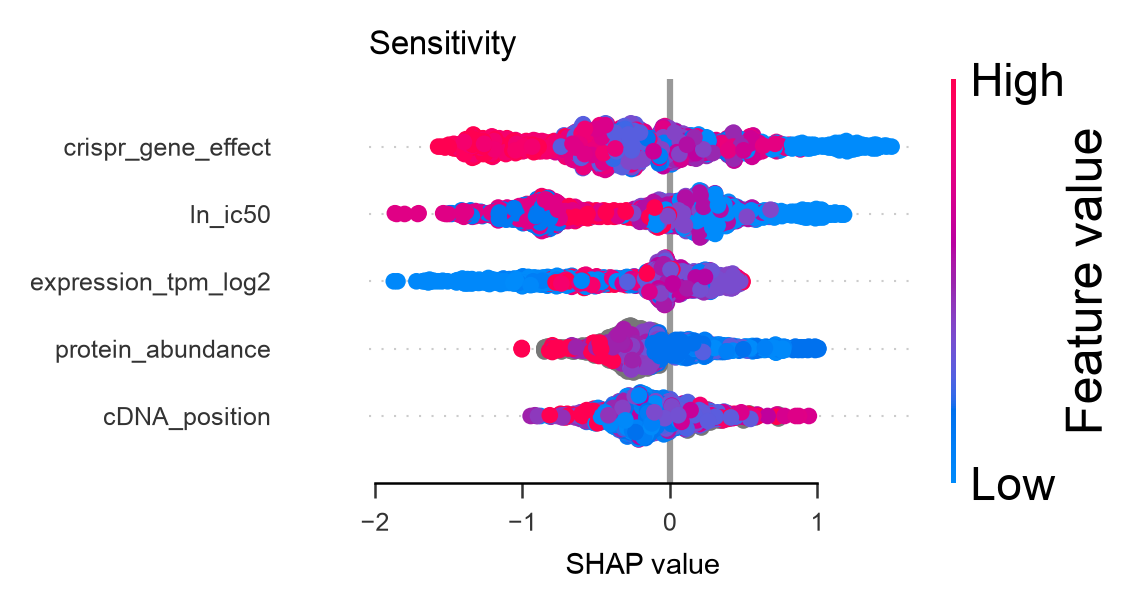

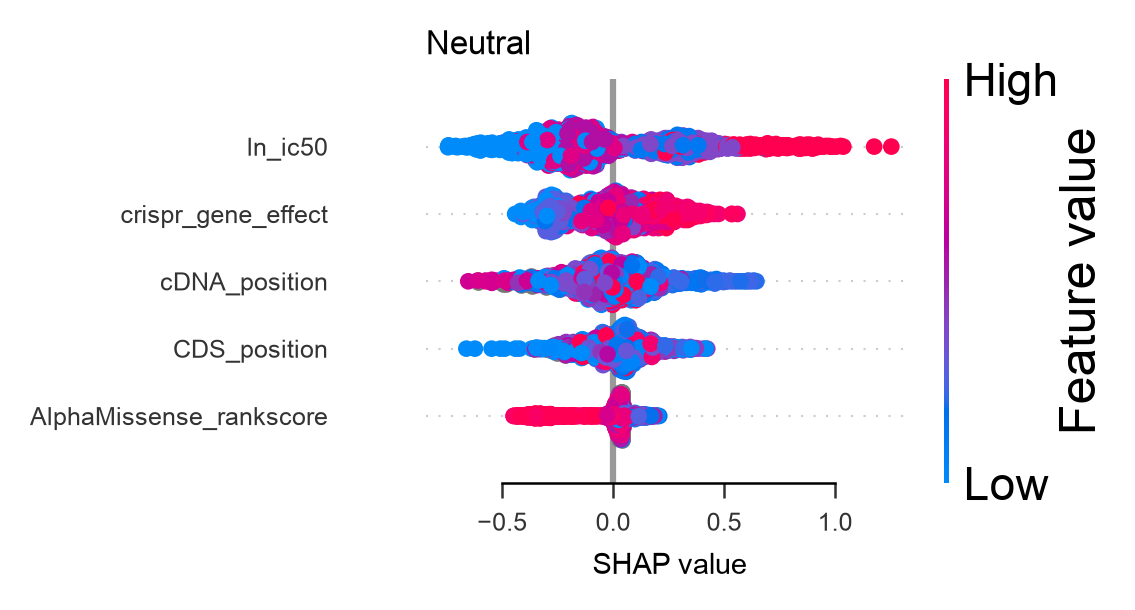

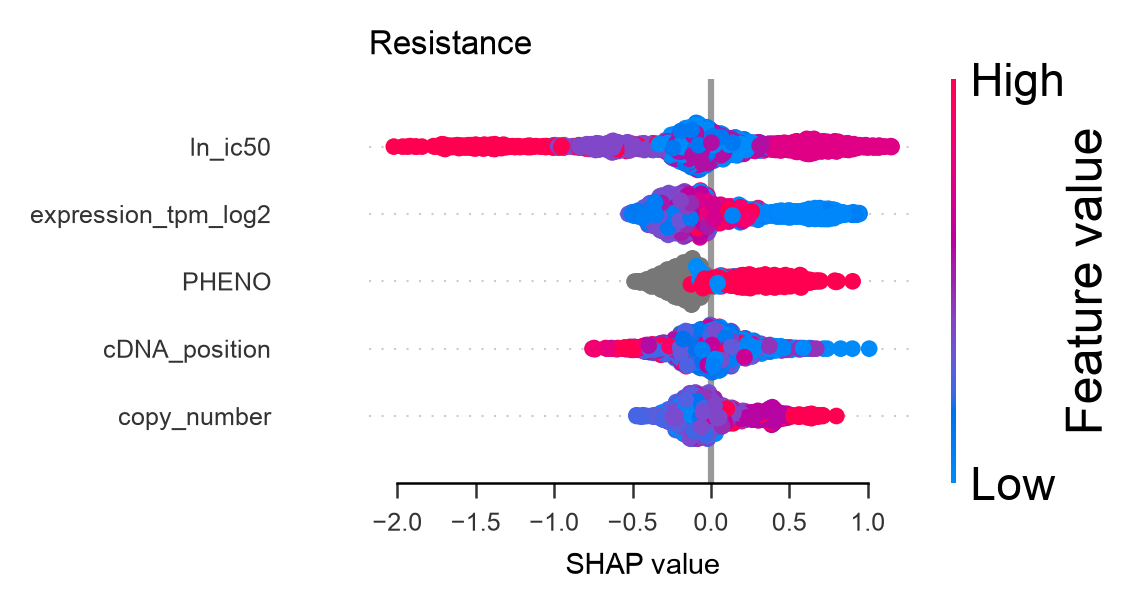

In [11]:
for name, index in CLASS_INDEX.items():
    order = list(mean_absolute[name].nlargest(5).index)
    positions = [ALL_FEATURES.index(column) for column in order]
    plt.figure(figsize=(3.8, 1.9))
    shap.summary_plot(
        values[:, positions, index],
        shap_features[order],
        feature_names=[c.replace("vep_", "") for c in order],
        plot_type="dot",
        max_display=5,
        show=False,
        plot_size=None,
    )
    plt.title(name.capitalize(), fontsize=8, loc="left")
    plt.xlabel("SHAP value", fontsize=7)
    plt.tick_params(labelsize=6)
    plt.tight_layout(pad=0.3)
    save_plot(plt.gcf(), f"shap_beeswarm_{name}")
    plt.show()

### Sensitivity against resistance importance

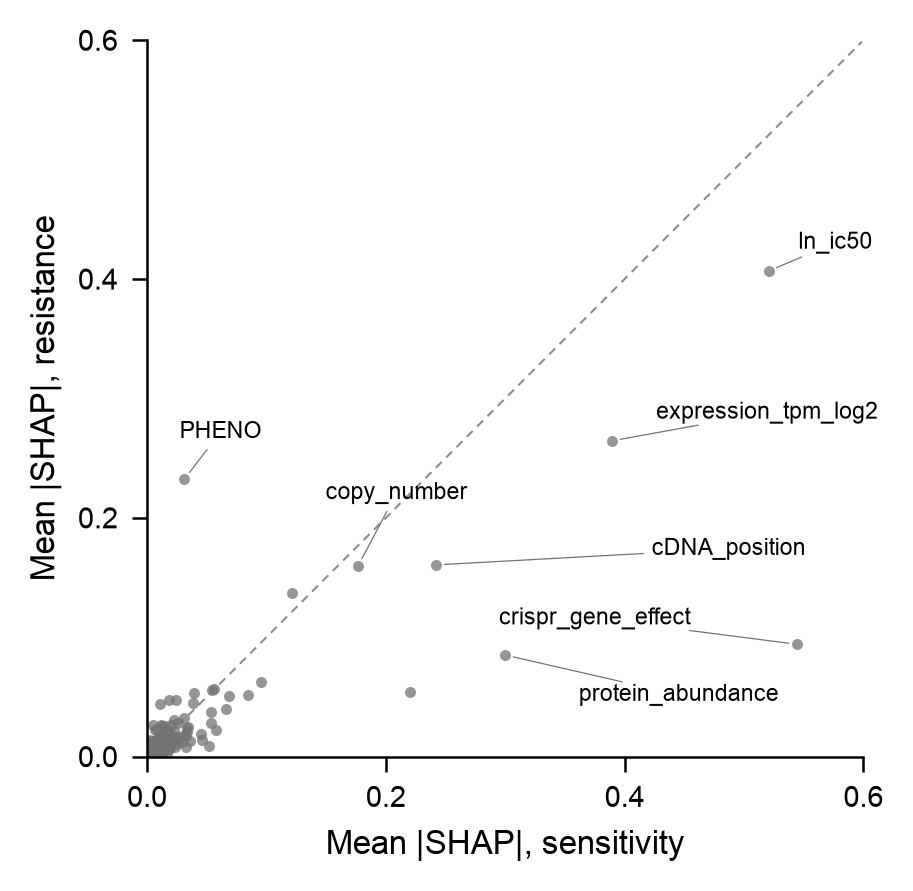

In [12]:
fig, ax = plt.subplots(figsize=(2.9, 2.9))
ax.scatter(
    mean_absolute["sensitivity"], mean_absolute["resistance"],
    s=7, linewidths=0, color="0.45", alpha=0.75,
)
limit = float(mean_absolute[["sensitivity", "resistance"]].to_numpy().max()) * 1.1
ax.plot([0, limit], [0, limit], **src.DIAGONAL)
extremes = pd.concat(
    [mean_absolute.nlargest(5, "sensitivity"), mean_absolute.nlargest(5, "resistance")]
).drop_duplicates()
texts = [
    ax.text(row.sensitivity, row.resistance, row.Index.replace("vep_", ""), fontsize=5.5)
    for row in extremes.itertuples()
]
adjust_text(
    texts, ax=ax, arrowprops=dict(arrowstyle="-", color="0.45", lw=0.3),
    expand=(1.8, 2.2), ensure_inside_axes=True,
)
ax.set_xlabel("Mean |SHAP|, sensitivity")
ax.set_ylabel("Mean |SHAP|, resistance")
ticked_axis(ax, "x", 0, limit)
ticked_axis(ax, "y", 0, limit)
ax.set_aspect("equal")
fig.tight_layout(pad=0.3)
save_plot(fig, "shap_sensitivity_vs_resistance")
plt.show()

### UMAP of the decision space

Concatenating the three classes' attributions gives each sample a full decision profile.

/Users/emanuel/miniconda3/envs/becr/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


embedding: (1724, 2)


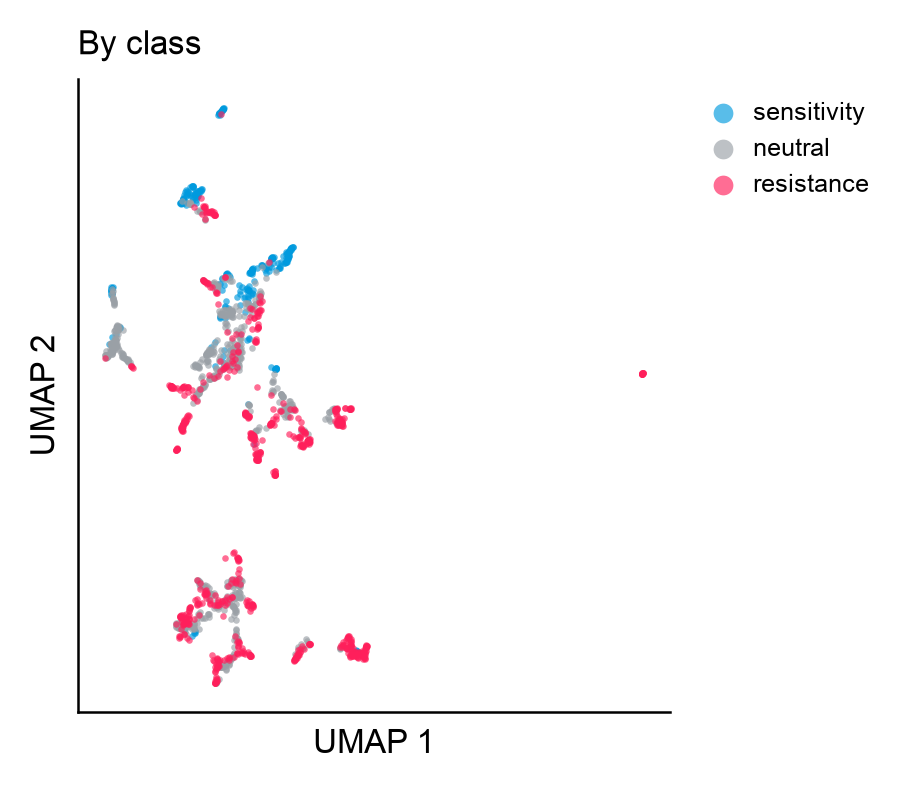

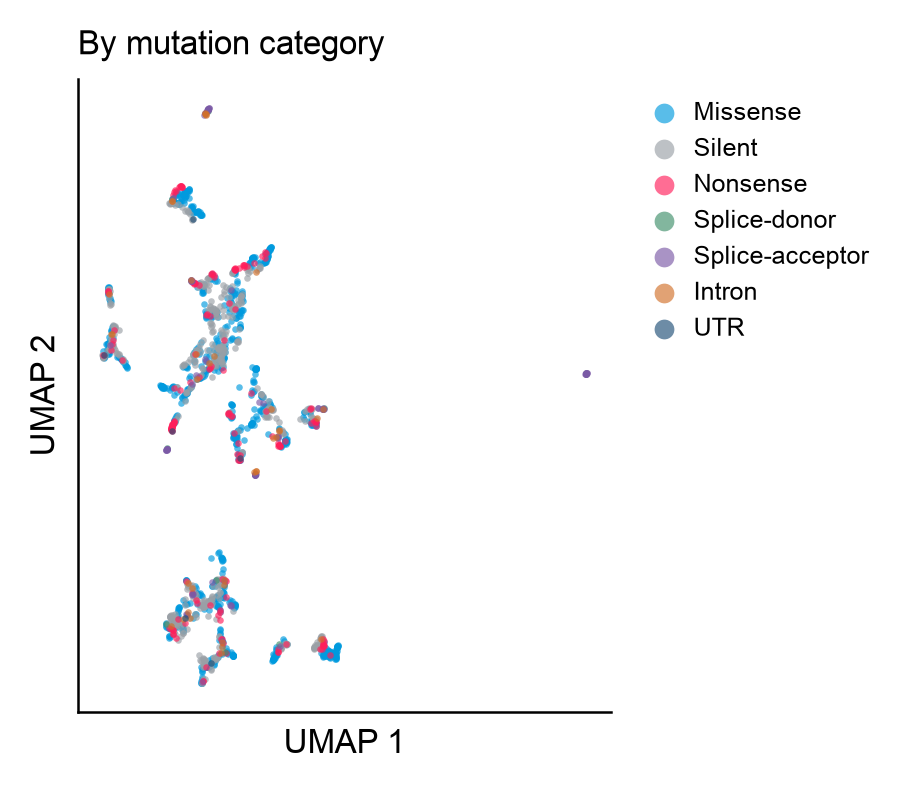

In [13]:
profile = np.concatenate([values[:, :, i] for i in range(len(CLASSES))], axis=1)
embedding = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(profile)
print("embedding:", embedding.shape)


def umap_panel(labels, palette, filename, title, order):
    fig, ax = plt.subplots(figsize=(2.9, 2.5))
    for group in order:
        mask = (labels == group).to_numpy()
        if not mask.any():
            continue
        ax.scatter(
            embedding[mask, 0], embedding[mask, 1], s=2.5, linewidths=0, alpha=0.65,
            color=palette.get(group, "0.6"), label=str(group), rasterized=True,
        )
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title(title, fontsize=8, loc="left")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(
        loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=6,
        markerscale=3, handletextpad=0.2,
    )
    fig.tight_layout(pad=0.3)
    save_plot(fig, filename)
    plt.show()


umap_panel(shap_frame.call, CLASS_COLOUR, "shap_umap_class", "By class", CLASSES)
present = [c for c in CATEGORY_ORDER if c in set(shap_frame.category.dropna())]
umap_panel(
    shap_frame.category, CATEGORY_COLOUR, "shap_umap_category",
    "By mutation category", present,
)

## Results table

In [14]:
final = summary.copy()
final.columns = [f"F1 {c}" if c != "macro" else "F1 macro" for c in final.columns]
for name, (value, _) in baselines.items():
    final.loc[name] = [np.nan, np.nan, np.nan, value]
final.round(3)

,F1 sensitivity,F1 neutral,F1 resistance,F1 macro
Full model,0.710,0.719,0.742,0.724
Cellular + drug context,0.702,0.677,0.697,0.692
Ensembl VEP,0.485,0.660,0.663,0.603
ProtVar,0.339,0.632,0.559,0.510
"Full model, no position or database flags",0.698,0.711,0.728,0.713
Always sensitivity,NaN,NaN,NaN,0.093
Always neutral,NaN,NaN,NaN,0.197
Always resistance,NaN,NaN,NaN,0.197
Uniform random,NaN,NaN,NaN,0.322
